# Task 2 & 3 (part 2) – Content-Based Filtering and a Weighted Hybrid
**INFO345 – RateBeer dataset**

In this notebook we build:
1. **Content-Based Filtering (CBF)** based on the content of each beer (style, brewery, country, alcohol %), following Lecture 2.
2. A **weighted hybrid** that combines CBF with Collaborative Filtering (SVD) using equal weights, **50% CBF + 50% CF**, following Lecture 7.

Both are evaluated exactly like in `02_models_and_evaluation.ipynb`: same data, same 5-fold cross validation, RMSE and MAE.

Requires `01_data_analysis.ipynb` to have been run first (it writes `filtered.parquet`).

## Loading the data

In [1]:
import pandas as pd
import numpy as np

DATA = ".."   # the 'RateBeer Dataset' folder

ratings = pd.read_parquet(f"{DATA}/filtered.parquet")[['user_id', 'beer_id', 'rating']]

# exactly the same sample as in notebook 02: at most 100 random ratings per user
ratings = ratings.sample(frac=1, random_state=42).groupby('user_id').head(100)

beers = pd.read_csv(f"{DATA}/beers.csv", low_memory=False)
breweries = pd.read_csv(f"{DATA}/breweries.csv")

print("Number of ratings:", len(ratings))
print("Number of users:", ratings['user_id'].nunique())
print("Number of beers:", ratings['beer_id'].nunique())

Number of ratings: 592205
Number of users: 10368
Number of beers: 88828


<details>
<summary><b>💡 What's going on here?</b></summary>

We load the same filtered ratings as in notebook 02 and take **exactly the same sample** (at most 100 random ratings per user, with the same `random_state=42`). That way the results of both notebooks can be compared directly.

We also load `beers.csv` (style, brewery and alcohol % of every beer) and `breweries.csv` (the country/region of every brewery). This is the *content* that content-based filtering uses.

</details>

## Content-Based Filtering
### Describing every beer by its content

In [2]:
# keep only the beers that appear in our ratings
items = beers[beers['beer_id'].isin(ratings['beer_id'].unique())].copy()

# add the country/region of the brewery
items['country'] = items['brewery_id'].map(breweries.set_index('id')['location'])

# group the alcohol percentage (ABV) into bins
abv_bins = [0, 3.5, 4.5, 5.5, 6.5, 7.5, 9, 11, 100]
abv_labels = ['under3.5', '3.5to4.5', '4.5to5.5', '5.5to6.5', '6.5to7.5', '7.5to9', '9to11', 'over11']
items['abv_bin'] = pd.cut(items['abv'], abv_bins, labels=abv_labels, right=False).astype(str)

# one "word" per feature, e.g. 'style_IndiaPaleAleIPA brewery_123 country_Norway abv_5.5to6.5'
def clean(s):
    return s.astype(str).str.replace(r'\W+', '', regex=True)

items['soup'] = ('style_' + clean(items['style']) +
                 ' brewery_' + items['brewery_id'].astype(str) +
                 ' country_' + clean(items['country'].fillna('unknown')) +
                 np.where(items['abv'].isna(), '', ' abv_' + items['abv_bin']))

items[['beer_id', 'beer_name', 'style', 'abv', 'country', 'soup']].head()

,beer_id,beer_name,style,abv,country,soup
1,105273,Castel Beer (Gabon),Pale Lager,5.2,Gabon,style_PaleLager brewery_3198 country_Gabon abv...
2,19445,Régab,Pale Lager,4.5,Gabon,style_PaleLager brewery_3198 country_Gabon abv...
25,437440,Boundary / Mad Hatter Milk Agitator,Berliner Weisse,4.1,Northern Ireland,style_BerlinerWeisse brewery_22818 country_Nor...
37,328951,Boundary American Pale Ale,American Pale Ale,3.5,Northern Ireland,style_AmericanPaleAle brewery_22818 country_No...
43,437438,Boundary Detre Ace*d 2,Saison,4.6,Northern Ireland,style_Saison brewery_22818 country_NorthernIre...


<details>
<summary><b>💡 What's going on here?</b></summary>

In Lecture 2 movies were described by their **genres**. Beers have no genres, so we use the four pieces of content we have about every beer:

- **style** (e.g. India Pale Ale, Imperial Stout),
- **brewery**,
- **country/region** of the brewery,
- **alcohol %** (ABV), grouped into 8 bins, because 6.1% and 6.2% should count as "the same".

Each beer becomes a short text (a "soup", like in the lab) with one word per feature, for example `style_PaleLager brewery_3198 country_Gabon abv_4.5to5.5`. The prefixes make sure that e.g. a style and a country can never be mistaken for the same word. If a beer has no ABV, that word is simply left out.

</details>

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# create beer vectors (one column per feature value), as with genres in Lecture 2
count = CountVectorizer(token_pattern=r'\S+', lowercase=False)
count_matrix = count.fit_transform(items['soup'])

# map each beer id to its row in count_matrix
item_index = pd.Series(range(len(items)), index=items['beer_id'].values)

print("count_matrix shape (beers x feature values):", count_matrix.shape)

count_matrix shape (beers x feature values): (88828, 10420)


<details>
<summary><b>💡 What's going on here?</b></summary>

Exactly as in Lecture 2, **`CountVectorizer`** turns every beer into a vector: one column for every possible feature value (every style, every brewery, every country, every ABV bin), with a **1** where the beer has that value and **0** otherwise.

The matrix has one row per beer and about 10,000 columns, but each row has only 3–4 ones, so it is stored as a *sparse* matrix (only the ones are kept in memory).

`item_index` remembers which row belongs to which beer id.

</details>

In [4]:
# Example: cosine similarity between a few beers (as in Lecture 2)
example = items[items['beer_name'].isin(['Heineken', 'Guinness Extra Stout', 'Nøgne Ø India Pale Ale',
                                          'Nøgne Ø Imperial Stout', 'Aass Bock'])].drop_duplicates('beer_name')
example_vectors = count_matrix[item_index[example['beer_id']].values]
pd.DataFrame(cosine_similarity(example_vectors).round(2),
             index=example['beer_name'], columns=example['beer_name'])

beer_name,Heineken,Guinness Extra Stout,Aass Bock,Nøgne Ø Imperial Stout,Nøgne Ø India Pale Ale
beer_name,,,,,
Heineken,1.0,0.0,0.00,0.00,0.00
Guinness Extra Stout,0.0,1.0,0.00,0.00,0.00
Aass Bock,0.0,0.0,1.00,0.25,0.25
Nøgne Ø Imperial Stout,0.0,0.0,0.25,1.00,0.50
Nøgne Ø India Pale Ale,0.0,0.0,0.25,0.50,1.00


<details>
<summary><b>💡 What's going on here?</b></summary>

A small example of **cosine similarity** (Lecture 2): 1 means two beers have exactly the same content, 0 means they have nothing in common.

With our four features the values are simple: each shared feature (same style, same brewery, same country, same ABV bin) adds about 0.25. For example, the two Nøgne Ø beers share brewery and country (0.5), the two Norwegian beers from different breweries share only the country (0.25), and Heineken and Guinness have nothing in common (0).

</details>

### The Content-Based Filtering recommender

In [5]:
from surprise import AlgoBase, PredictionImpossible

class ContentBasedFiltering(AlgoBase):
    '''Content-Based Filtering as a Surprise algorithm.

    To predict how user u will rate beer i, we look at the beers u has already rated,
    take the k most similar ones (cosine similarity of their content) and return the
    similarity-weighted average of u's ratings of those beers (rating prediction, Lecture 2).
    '''
    def __init__(self, k=40):
        AlgoBase.__init__(self)
        self.k = k

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        # normalise the beer vectors to length 1, so a dot product = cosine similarity
        lengths = np.sqrt(np.asarray(count_matrix.multiply(count_matrix).sum(axis=1))).ravel()
        self.vectors = count_matrix.multiply(1 / lengths[:, None]).tocsr()
        # for every user: which beers (rows in count_matrix) they rated, and how
        self.user_rows, self.user_ratings = {}, {}
        for u, user_items in trainset.ur.items():
            self.user_rows[u] = np.array([item_index[trainset.to_raw_iid(i)] for i, _ in user_items])
            self.user_ratings[u] = np.array([r for _, r in user_items])
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_user(u):
            raise PredictionImpossible('User is unknown.')
        if self.trainset.knows_item(i):
            beer_id = self.trainset.to_raw_iid(i)
        else:
            # a beer with no ratings in the training set: Surprise passes it as 'UKN__<beer id>'.
            # CBF can still use its content, so we recover the beer id.
            beer_id = int(str(i).replace('UKN__', ''))
        # similarity between beer i and every beer the user has rated
        x = self.vectors[item_index[beer_id]]
        sims = np.asarray((self.vectors[self.user_rows[u]] @ x.T).todense()).ravel()
        # the k most similar beers the user has rated
        top = np.argsort(-sims)[:self.k]
        if sims[top].sum() == 0:
            raise PredictionImpossible('No similar beers.')
        # similarity-weighted average of the user's ratings of those beers
        return sims[top] @ self.user_ratings[u][top] / sims[top].sum()

<details>
<summary><b>💡 What's going on here?</b></summary>

This is the content-based recommender, written as a **Surprise algorithm** (like `ContentBasedFiltering()` in Lab 3), so it can be evaluated with exactly the same `cross_validate` code as SVD and KNN.

**How it predicts how user *u* will rate beer *i*:**
1. Find all beers *u* has rated in the training set.
2. Compute the cosine similarity between beer *i* and each of them (based on content only).
3. Take the **k = 40 most similar** ones.
4. Predict the **similarity-weighted average** of *u*'s ratings of those beers: beers that are very similar to *i* count more.

So if you rated three IPAs from Norwegian breweries highly, a new Norwegian IPA gets a high predicted rating – *"show me more of what I liked"*.

**New beers:** CBF does not need any ratings of beer *i* itself – only its content. So it also works for beers with no ratings in the training set (Surprise passes those as `'UKN__<beer id>'`, and we look up the content of that beer id). This is exactly where collaborative filtering has nothing to go on.

If the user has rated nothing similar at all, the algorithm raises `PredictionImpossible`, and Surprise then falls back to the overall average rating.

</details>

## Weighted Hybrid: 50% CBF + 50% CF

In [6]:
class WeightedHybrid(AlgoBase):
    '''Weighted hybrid (Lecture 7): the prediction is a weighted sum of the
    predictions of several recommenders, rec_w = b1 * rec_1 + b2 * rec_2.'''
    def __init__(self, algorithms, weights):
        AlgoBase.__init__(self)
        self.algorithms = algorithms
        self.weights = weights

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        for algorithm in self.algorithms:
            algorithm.fit(trainset)
        return self

    def estimate(self, u, i):
        prediction = 0
        for algorithm, weight in zip(self.algorithms, self.weights):
            try:
                estimate = algorithm.estimate(u, i)
                if isinstance(estimate, tuple):     # some Surprise algorithms return (estimate, details)
                    estimate = estimate[0]
            except PredictionImpossible:
                estimate = self.trainset.global_mean  # same fallback as Surprise uses
            prediction += weight * estimate
        return prediction

<details>
<summary><b>💡 What's going on here?</b></summary>

The **weighted hybrid** from Lecture 7: two recommenders each make a prediction, and the hybrid returns a weighted sum of them:

> **hybrid = 0.5 × CBF prediction + 0.5 × SVD prediction**

Both models predict a rating on the same scale (0.5–5), so we can average them directly – no rescaling is needed. If one of the two models cannot make a prediction, its part is replaced by the overall average rating, which is exactly what Surprise does on its own too.

The idea: CBF knows *what the beer is* (style, brewery, ...), while CF/SVD knows *how people with similar taste rated it*. Combining them can make up for the weaknesses of each.

</details>

## Evaluation with 5-fold cross validation

In [7]:
from surprise import SVD, BaselineOnly, NormalPredictor, Reader, Dataset
from surprise.model_selection import cross_validate, KFold
from tabulate import tabulate
import time, datetime

reader = Reader(rating_scale=(0.5, 5))
data = Dataset.load_from_df(ratings[['user_id', 'beer_id', 'rating']], reader)

np.random.seed(0)
kf = KFold(n_splits=5, random_state=0)

<details>
<summary><b>💡 What's going on here?</b></summary>

The same setup as in notebook 02: the same rating scale, the same data and **the same 5 folds** (`random_state=0`), so every model is trained and tested on exactly the same splits.

</details>

In [8]:
recommenders = [ContentBasedFiltering(),
                SVD(random_state=0),
                WeightedHybrid([ContentBasedFiltering(), SVD(random_state=0)], [0.5, 0.5]),
                BaselineOnly(verbose=False),
                NormalPredictor()]
titles = ['Content-Based (CBF)', 'SVD (CF)', 'Hybrid 50% CBF + 50% CF', 'Baseline', 'Random']

table = []
for algo, title in zip(recommenders, titles):
    start = time.time()
    result = cross_validate(algo, data, ['rmse', 'mae'], kf)
    cv_time = str(datetime.timedelta(seconds=int(time.time() - start)))
    table.append([title, '{:.3f}'.format(np.mean(result['test_rmse'])),
                  '{:.3f}'.format(np.mean(result['test_mae'])), cv_time])
    print(title, "done in", cv_time)

Content-Based (CBF) done in 0:03:37


SVD (CF) done in 0:01:12


Hybrid 50% CBF + 50% CF done in 0:04:55


Baseline done in 0:00:28


Random done in 0:00:20


<details>
<summary><b>💡 What's going on here?</b></summary>

We run 5-fold cross validation for five models:

- **Content-Based (CBF)** – our content-based recommender on its own,
- **SVD (CF)** – the collaborative filtering half of the hybrid,
- **Hybrid 50% CBF + 50% CF** – our main model,
- **Baseline** and **Random** – the simple reference models from notebook 02.

SVD gets `random_state=0` here so the results are exactly reproducible. (In notebook 02 SVD was run without a fixed seed, so its numbers can differ in the third decimal.)

</details>

### Results

In [9]:
header = ['Recommenders', 'Pred Accuracy [RMSE]', 'Pred Accuracy [MAE]']
print(tabulate([row[:3] for row in table], header, tablefmt="pipe"))
print()
print(tabulate(table, header + ['Time'], tablefmt="pipe"))

| Recommenders            |   Pred Accuracy [RMSE] |   Pred Accuracy [MAE] |
|:------------------------|-----------------------:|----------------------:|
| Content-Based (CBF)     |                  0.592 |                 0.436 |
| SVD (CF)                |                  0.533 |                 0.392 |
| Hybrid 50% CBF + 50% CF |                  0.539 |                 0.396 |
| Baseline                |                  0.532 |                 0.39  |
| Random                  |                  1.001 |                 0.79  |

| Recommenders            |   Pred Accuracy [RMSE] |   Pred Accuracy [MAE] | Time    |
|:------------------------|-----------------------:|----------------------:|:--------|
| Content-Based (CBF)     |                  0.592 |                 0.436 | 0:03:37 |
| SVD (CF)                |                  0.533 |                 0.392 | 0:01:12 |
| Hybrid 50% CBF + 50% CF |                  0.539 |                 0.396 | 0:04:55 |
| Baseline               

<details>
<summary><b>💡 What's going on here?</b></summary>

Same format as before: **lower is better**, 0 would be perfect, and the numbers are errors in rating points (not percentages).

Compare the hybrid with **both of its halves**: is the combination better than CBF alone *and* better than SVD alone? The interpretation below the next analyses discusses this.

</details>

## Extra analysis
### Is 50/50 the best mix?
Lecture 7 asks how to choose the weights β₁ and β₂. Because the hybrid is just a weighted sum, we can get the CBF and SVD predictions once per fold and combine them with any weight, without training again.

In [10]:
weights = [0, 0.25, 0.5, 0.75, 1]       # share of CBF in the hybrid
rows = []
all_predictions = []
for fold, (trainset, testset) in enumerate(kf.split(data)):
    cbf_pred = ContentBasedFiltering().fit(trainset).test(testset)
    svd_pred = SVD(random_state=0).fit(trainset).test(testset)
    cbf = np.array([p.est for p in cbf_pred])
    svd = np.array([p.est for p in svd_pred])
    true = np.array([p.r_ui for p in cbf_pred])
    # how many ratings each test beer has in this fold's training set
    counts = {trainset.to_raw_iid(i): len(r) for i, r in trainset.ir.items()}
    n_train = np.array([counts.get(p.iid, 0) for p in cbf_pred])
    all_predictions.append(pd.DataFrame({'cbf': cbf, 'svd': svd, 'true': true, 'n_train': n_train}))
    for w in weights:
        hybrid = w * cbf + (1 - w) * svd
        rows.append({'fold': fold, 'CBF weight': w,
                     'RMSE': np.sqrt(np.mean((hybrid - true) ** 2)),
                     'MAE': np.mean(np.abs(hybrid - true))})
    print("fold", fold + 1, "done")

weight_results = pd.DataFrame(rows).groupby('CBF weight')[['RMSE', 'MAE']].mean().round(3)
weight_results.index = ['0 (pure SVD)', '0.25', '0.5 (our hybrid)', '0.75', '1 (pure CBF)']
weight_results

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


,RMSE,MAE
0 (pure SVD),0.533,0.392
0.25,0.530,0.389
0.5 (our hybrid),0.539,0.396
0.75,0.560,0.412
1 (pure CBF),0.592,0.436


<details>
<summary><b>💡 What's going on here?</b></summary>

For each of the 5 folds we train CBF and SVD once, store their predictions for the test ratings, and then combine them with different weights: 0% CBF (= pure SVD), 25%, **50% (our hybrid)**, 75% and 100% CBF (= pure CBF). The table shows the average RMSE and MAE over the 5 folds.

**Important:** this uses the test folds, so it is an *analysis* of how sensitive the hybrid is to the weight – not a fair way to *choose* the weight. Choosing the weight properly would need a separate validation set.

We also store, for every test rating, how many ratings that beer has in the training set. We use that in the next analysis.

</details>

,test ratings,RMSE CBF,RMSE SVD,RMSE Hybrid 50/50
ratings of the beer in training,,,,
0,39930.0,0.565,0.599,0.570
1-2,71683.0,0.589,0.606,0.584
3-5,67056.0,0.592,0.574,0.567
6-10,68351.0,0.588,0.539,0.547
11-25,103467.0,0.588,0.512,0.528
26-100,147368.0,0.586,0.489,0.509
over 100,94350.0,0.623,0.498,0.524


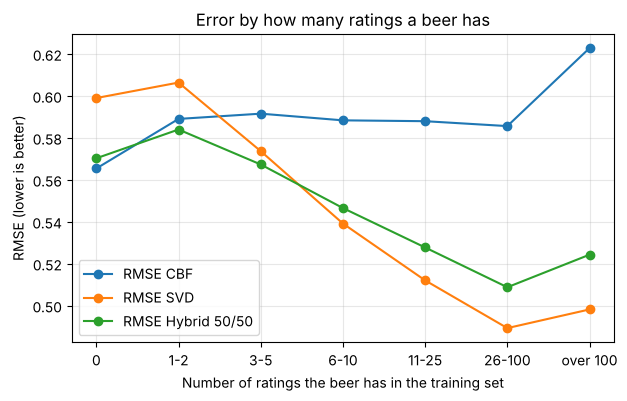

In [11]:
import matplotlib.pyplot as plt
preds = pd.concat(all_predictions, ignore_index=True)
preds['hybrid'] = 0.5 * preds['cbf'] + 0.5 * preds['svd']

# group the test ratings by how many training ratings the beer has
groups = pd.cut(preds['n_train'], [-1, 0, 2, 5, 10, 25, 100, 100000],
                labels=['0', '1-2', '3-5', '6-10', '11-25', '26-100', 'over 100'])
by_popularity = preds.groupby(groups, observed=True).apply(
    lambda g: pd.Series({'test ratings': len(g),
                         'RMSE CBF': np.sqrt(np.mean((g.cbf - g.true) ** 2)),
                         'RMSE SVD': np.sqrt(np.mean((g.svd - g.true) ** 2)),
                         'RMSE Hybrid 50/50': np.sqrt(np.mean((g.hybrid - g.true) ** 2))}))
by_popularity.index.name = 'ratings of the beer in training'
display(by_popularity.round(3))

ax = by_popularity[['RMSE CBF', 'RMSE SVD', 'RMSE Hybrid 50/50']].plot(marker='o', figsize=(7, 4))
ax.set(xlabel='Number of ratings the beer has in the training set', ylabel='RMSE (lower is better)',
       title='Error by how many ratings a beer has')
plt.grid(alpha=0.3)
plt.savefig('figures/fig5_rmse_by_beer_popularity.png', dpi=150, bbox_inches='tight')
plt.show()

<details>
<summary><b>💡 What's going on here?</b></summary>

Task 1 showed that most beers have very few ratings. Here we check **how well each model predicts depending on how many ratings the beer has** in the training set.

Collaborative filtering (SVD) learns about a beer only from its ratings, so it should struggle with beers that have 0–2 ratings (with 0 ratings SVD knows nothing about the beer at all). CBF only needs the beer's content, so it should not depend on that as much. If that is true, the hybrid should be most useful for **rarely rated beers** – the long tail – even if it does not win on average.

The figure is saved as `figures/fig5_rmse_by_beer_popularity.png` for the report.

</details>

#### Which method performs best?
*(Discuss the results here.)*

<details>
<summary><b>💡 Suggested interpretation</b></summary>

- **On average, SVD alone is slightly better than the 50/50 hybrid** (RMSE 0.533 vs 0.539). CBF alone is clearly weaker (0.592), so giving it half the weight pulls the average down a little. All three beat Random by far.
- **The weight matters:** 25% CBF + 75% SVD (RMSE 0.530) is marginally better than SVD alone, while more than 50% CBF makes the hybrid worse. (This was measured on the test folds, so it is an analysis, not a fair way to pick the weight.)
- **The picture changes for rarely rated beers** – the long tail from Task 1:
  - Beers with **0 ratings** in training: CBF 0.565 vs SVD 0.599. SVD knows nothing about these beers, while CBF still knows their style, brewery, country and ABV.
  - Beers with **1–5 ratings**: the **hybrid is the best of the three** (0.584 and 0.567).
  - Beers with **more than 5 ratings**: SVD is best, and the hybrid is slightly worse because the CBF half adds error.
  - About **30%** of the test ratings are for beers with 5 or fewer ratings in training, so this is not a small corner case.
- **Conclusion:** a fixed 50/50 mix is a compromise. Content helps exactly where collaborative filtering has too little data (new and rare beers), and hurts where collaborative filtering has enough. A natural improvement – for future work – is to let the weight depend on how many ratings a beer has (more CBF for new beers, more CF for popular ones).

</details>